In [11]:
seed = 42
eval_steps = 10

In [12]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import ConfusionMatrixDisplay

In [13]:
print(tf.config.list_physical_devices())

[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [14]:
tf.keras.utils.set_random_seed(seed)

model = Sequential([
    Input(shape=(29,)),
    Dense(64, activation='tanh'),
    Dense(32, activation='tanh'),
    Dense(16, activation='tanh'),
    Dense(8, activation='tanh'),
    Dense(4, activation='tanh'),
    Dense(2, activation='tanh'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', 'f1_score', 'recall', 'precision']
)

In [24]:
data = pd.read_csv("data/creditcard_2023.csv").drop(columns=["id"], errors="ignore")
print(f"There are a total of {data.isna().sum().sum()} missing values in the dataset.")

x = data.drop(columns=["Class"])
y = data["Class"]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.15, random_state=seed, stratify=y
)

scaler = RobustScaler()
x_train = pd.DataFrame(
    scaler.fit_transform(x_train), columns=x_train.columns, index=x_train.index
)
x_test = pd.DataFrame(
    scaler.transform(x_test), columns=x_test.columns, index=x_test.index
)

There are a total of 0 missing values in the dataset.


In [ ]:
model.fit(
    x_train,
    y_train,
    epochs=25,
    batch_size=2048,
    validation_split=0.1
)
model.evaluate(x_test, y_test, return_dict=True)

Epoch 1/25
213/213 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9516 - f1_score: 0.6666 - loss: 0.2702 - precision: 0.9759 - recall: 0.9261 - val_accuracy: 0.9715 - val_f1_score: 0.6672 - val_loss: 0.2018 - val_precision: 0.9778 - val_recall: 0.9650
Epoch 2/25
213/213 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9792 - f1_score: 0.6666 - loss: 0.1664 - precision: 0.9853 - recall: 0.9728 - val_accuracy: 0.9854 - val_f1_score: 0.6672 - val_loss: 0.1349 - val_precision: 0.9900 - val_recall: 0.9807
Epoch 3/25
213/213 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9894 - f1_score: 0.6666 - loss: 0.1132 - precision: 0.9906 - recall: 0.9881 - val_accuracy: 0.9925 - val_f1_score: 0.6672 - val_loss: 0.0935 - val_precision: 0.9923 - val_recall: 0.9928
Epoch 4/25
213/213 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9944 - f1_score: 0.6666 - loss: 0.0802 - precision: 0.9935 - recall: 0.9953 - val_accuracy: 0.9963 - val_f1_score: 0.6672 - val_loss: 0.0677 - val_precision: 0.9950 - val_recall:

{'accuracy': 0.9989448189735413,
 'f1_score': 0.6666613817214966,
 'loss': 0.006930242758244276,
 'precision': 0.998407244682312,
 'recall': 0.999484121799469}

In [17]:
test_metrics = model.evaluate(x_test, y_test, return_dict=True, verbose=0)
for metric_name, metric_value in test_metrics.items():
    print(f'Test {metric_name}: {metric_value:.4f}')

Test accuracy: 0.9989
Test f1_score: 0.6667
Test loss: 0.0069
Test precision: 0.9984
Test recall: 0.9995


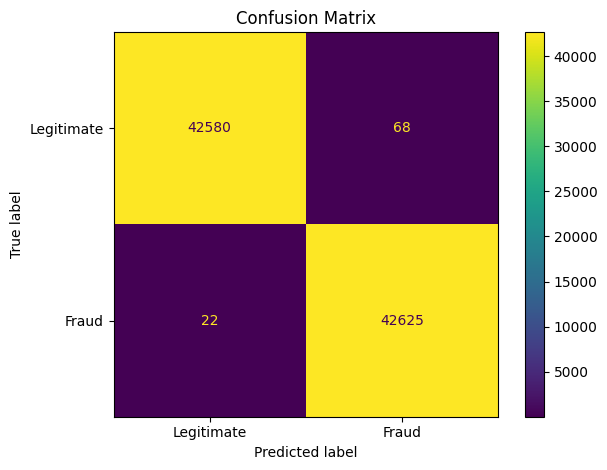

In [18]:
y_prob = model.predict(x_test, verbose=0).ravel()
# Convert predicted probabilities to binary class predictions
y_pred = (y_prob >= 0.5).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['Legitimate', 'Fraud']
)
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()